# Chatbot UMKM "Kopi Senja" - Fine-tuning Qwen dengan QLoRA

Alur aplikasi: **Teks -> Qwen (+ adapter LoRA) -> Teks**

**Cara pakai**
1. `Runtime -> Change runtime type -> T4 GPU`.
2. Jalankan sel **satu per satu dari atas ke bawah** (jangan lompat).
3. Hanya sel **"Basis pengetahuan"** yang perlu Anda sesuaikan (nama toko, menu, harga, info).
4. Semua hasil (dataset, adapter, tabel evaluasi, grafik) tersimpan otomatis di Google Drive.

## 1. Instalasi library

In [1]:
   !pip install -q -U transformers peft accelerate bitsandbytes datasets gradio

KeyboardInterrupt: 

## 2. Konfigurasi dan Google Drive

In [1]:
import os, json, random, re
import torch
from google.colab import drive

drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/Tugas_AI_Qwen"
os.makedirs(BASE, exist_ok=True)

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"   # jika memori GPU kurang: "Qwen/Qwen2.5-0.5B-Instruct"
ADAPTER_DIR = f"{BASE}/adapter_kopi_senja"
SEED = 42
random.seed(SEED)

# System prompt yang SAMA dipakai untuk model dasar dan model fine-tuned (perbandingan adil)
SYSTEM_PROMPT = "Kamu adalah asisten virtual Kopi Senja. Jawab dalam bahasa Indonesia dengan ramah dan singkat."

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("TIDAK ADA GPU -> ganti runtime ke T4 GPU lalu jalankan ulang dari sel 2")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4


## 3. Basis pengetahuan toko (fiktif)
Semua data di sini **karangan**. Boleh diganti sesuka Anda, tetapi pastikan **konsisten** (harga, jam, dll).
Setiap jawaban nanti dibuat dari data ini, sehingga dataset dan kunci evaluasi selalu cocok.

In [ ]:
def rp(angka):
    return "Rp" + f"{angka:,}".replace(",", ".")

# (nama, kategori, harga, deskripsi)
MENU = [
    ("Espresso", "Kopi", 15000, "Espresso murni dari campuran arabika dan robusta, rasanya pekat dan kuat, disajikan single shot."),
    ("Americano", "Kopi", 18000, "Espresso yang ditambah air panas atau es, rasanya ringan dan bersih."),
    ("Kopi Susu Senja", "Kopi", 22000, "Menu andalan Kopi Senja: espresso, susu segar, dan gula aren dengan rasa manis legit."),
    ("Cappuccino", "Kopi", 24000, "Espresso dengan susu panas dan busa susu yang tebal."),
    ("Cafe Latte", "Kopi", 25000, "Espresso dengan susu steam yang lembut, rasanya creamy."),
    ("Caramel Macchiato", "Kopi", 28000, "Latte dengan sirup vanila dan saus karamel di atasnya."),
    ("V60 Manual Brew", "Kopi", 27000, "Seduhan manual V60 dari biji single origin pilihan barista, rasanya bersih dan aromatik."),
    ("Es Kopi Gula Aren", "Kopi", 20000, "Kopi dingin dengan sedikit susu dan gula aren cair, lebih ringan daripada Kopi Susu Senja."),
    ("Matcha Latte", "Non-Kopi", 26000, "Matcha dengan susu, bisa disajikan panas atau dingin."),
    ("Cokelat Panas", "Non-Kopi", 22000, "Cokelat pekat dengan susu panas dan sedikit krim."),
    ("Es Teh Lemon", "Non-Kopi", 15000, "Teh dingin dengan perasan lemon segar."),
    ("Croissant Butter", "Makanan Ringan", 20000, "Croissant renyah dengan mentega, dipanggang setiap pagi."),
    ("Roti Bakar Cokelat Keju", "Makanan Ringan", 18000, "Roti tebal yang dibakar dengan selai cokelat dan parutan keju."),
    ("Kentang Goreng", "Makanan Ringan", 17000, "Kentang goreng renyah dengan saus sambal atau mayones."),
    ("Brownies", "Makanan Ringan", 20000, "Brownies cokelat padat dengan taburan kacang almond."),
    ("Nasi Goreng Kampung", "Makanan Berat", 28000, "Nasi goreng bumbu rempah dengan telur dan ayam suwir."),
    ("Mie Goreng Senja", "Makanan Berat", 26000, "Mie goreng dengan sayuran, telur, dan bakso."),
]
HARGA = {n: h for n, k, h, d in MENU}

# Informasi umum toko: topik, daftar pertanyaan (untuk training), jawaban
INFO = [
    {"topik": "jam_buka",
     "tanya": ["Jam berapa Kopi Senja buka?", "Buka jam berapa?", "Jam operasional toko ini apa?", "Kapan kalian buka dan tutup?", "Tutup jam berapa?"],
     "jawab": "Kopi Senja buka Senin-Jumat pukul 08.00-22.00, Sabtu-Minggu pukul 07.00-23.00, dan hari libur nasional pukul 09.00-21.00."},
    {"topik": "alamat",
     "tanya": ["Alamat Kopi Senja di mana?", "Lokasi tokonya di mana ya?", "Kopi Senja ada di daerah mana?", "Minta alamat lengkapnya dong."],
     "jawab": "Kopi Senja berada di Jl. Melati No. 12, Kota Bandung, dekat Taman Kota."},
    {"topik": "kontak",
     "tanya": ["Nomor WhatsApp Kopi Senja berapa?", "Bagaimana cara menghubungi Kopi Senja?", "Ada Instagram atau kontak yang bisa dihubungi?", "Minta kontak admin dong."],
     "jawab": "Kakak bisa menghubungi kami lewat WhatsApp di 0812-0000-1234 atau Instagram @kopisenja.id."},
    {"topik": "pembayaran",
     "tanya": ["Metode pembayaran apa saja yang diterima?", "Bisa bayar pakai QRIS?", "Terima pembayaran apa aja di sini?", "Apakah bisa bayar pakai kartu debit?"],
     "jawab": "Kami menerima tunai, QRIS, dan kartu debit. Kartu kredit belum bisa kami terima."},
    {"topik": "wifi",
     "tanya": ["Ada Wi-Fi gratis tidak?", "Wifi-nya gratis nggak?", "Nama dan sandi wifi Kopi Senja apa?", "Bagaimana cara konek ke wifi?"],
     "jawab": "Ada Wi-Fi gratis untuk pelanggan. Nama jaringannya KopiSenja_Guest dan kata sandinya senja2026."},
    {"topik": "colokan",
     "tanya": ["Apakah ada colokan listrik?", "Bisa ngecas laptop di sini?", "Tersedia stop kontak di meja nggak?", "Cocok buat kerja atau ngerjain tugas?"],
     "jawab": "Tersedia colokan listrik di hampir semua meja, terutama di area dalam dan dekat jendela, jadi nyaman untuk bekerja atau mengerjakan tugas."},
    {"topik": "reservasi",
     "tanya": ["Bisa reservasi tempat?", "Bagaimana cara booking meja?", "Reservasi untuk rombongan bisa nggak?", "Kalau datang ramai-ramai perlu pesan tempat dulu?"],
     "jawab": "Reservasi tersedia untuk minimal 6 orang lewat WhatsApp 0812-0000-1234, paling lambat sehari sebelumnya. Untuk kurang dari 6 orang, kami melayani tanpa reservasi sesuai ketersediaan tempat."},
    {"topik": "kapasitas",
     "tanya": ["Kopi Senja muat berapa orang?", "Tempatnya luas nggak? Berapa kursinya?", "Berapa jumlah kursi di sini?", "Ada area indoor dan outdoor?"],
     "jawab": "Kopi Senja punya sekitar 40 kursi, terbagi di area dalam ber-AC dan area teras."},
    {"topik": "happy_hour",
     "tanya": ["Ada promo happy hour?", "Ada diskon atau promo apa saja?", "Kapan jam promo berlaku?", "Promo untuk minuman kopi apa ya?"],
     "jawab": "Happy Hour berlaku Senin-Kamis pukul 14.00-17.00 dengan diskon 20% untuk semua minuman kopi."},
    {"topik": "member",
     "tanya": ["Ada kartu member?", "Apa itu Senja Club?", "Bagaimana daftar member?", "Ada program loyalitas pelanggan?"],
     "jawab": "Ada Senja Club, program member gratis. Daftar di kasir, dan setiap pembelian 10 minuman kakak mendapat 1 minuman gratis."},
    {"topik": "susu_oat",
     "tanya": ["Bisa ganti susu dengan susu oat?", "Ada pilihan susu nabati?", "Apakah ada susu oat?", "Minuman berbasis susu pakai susu apa?"],
     "jawab": "Minuman berbasis susu kami menggunakan susu sapi. Kakak bisa mengganti dengan susu oat dengan tambahan Rp5.000."},
    {"topik": "alergi",
     "tanya": ["Ada menu yang mengandung kacang?", "Saya alergi kacang, menu mana yang harus dihindari?", "Menu apa yang mengandung alergen?", "Brownies aman untuk alergi kacang?"],
     "jawab": "Brownies mengandung kacang almond, jadi sebaiknya dihindari oleh yang alergi kacang. Minuman berbasis susu mengandung susu sapi. Beri tahu kasir jika ada alergi agar kami bantu pilihkan menu."},
    {"topik": "ukuran",
     "tanya": ["Ada ukuran minuman apa saja?", "Bisa pesan ukuran besar?", "Ukuran large tambah berapa?", "Minuman ada ukuran regular dan large?"],
     "jawab": "Minuman tersedia ukuran regular dan large. Ukuran large tambah Rp5.000, kecuali Espresso dan V60 yang hanya tersedia ukuran regular."},
    {"topik": "gula",
     "tanya": ["Bisa atur tingkat manis?", "Boleh kurangi gula?", "Ada opsi tanpa gula?", "Kalau saya tidak mau terlalu manis bagaimana?"],
     "jawab": "Bisa, Kak. Tingkat kemanisan dapat diatur: normal, less sugar, atau tanpa gula. Sebutkan saja saat memesan."},
    {"topik": "parkir",
     "tanya": ["Ada parkir?", "Parkir motor gratis?", "Tersedia lahan parkir mobil?", "Kalau bawa kendaraan parkirnya di mana?"],
     "jawab": "Parkir motor dan mobil gratis, tetapi kapasitas mobil terbatas, sekitar 6 kendaraan."},
    {"topik": "antar",
     "tanya": ["Bisa pesan antar?", "Ada layanan delivery?", "Bagaimana cara pesan online?", "Pesan lewat ojek online bisa?"],
     "jawab": "Pesan antar tersedia lewat aplikasi ojek online dalam radius 5 km dari toko, pukul 10.00-21.00."},
    {"topik": "biji_kopi",
     "tanya": ["Jual biji kopi?", "Bisa beli biji kopi untuk dibawa pulang?", "Ada kopi kemasan?", "Berapa harga biji kopi per kemasan?"],
     "jawab": "Kami menjual biji kopi kemasan 200 gram: arabika Gayo Rp85.000 dan robusta Temanggung Rp70.000. Bisa digiling sesuai alat seduh kakak."},
    {"topik": "merokok",
     "tanya": ["Ada area merokok?", "Boleh merokok di Kopi Senja?", "Smoking area di mana?", "Apakah area dalam bebas rokok?"],
     "jawab": "Area merokok hanya di teras luar. Area dalam bebas asap rokok."},
    {"topik": "halal",
     "tanya": ["Apakah menunya halal?", "Ada menu yang mengandung alkohol atau babi?", "Semua menu aman untuk muslim?", "Status halal makanannya bagaimana?"],
     "jawab": "Seluruh menu kami halal dan tidak mengandung alkohol maupun babi."},
    {"topik": "fasilitas",
     "tanya": ["Ada musala?", "Tersedia toilet di dalam?", "Fasilitas apa saja yang ada?", "Ada tempat salat?"],
     "jawab": "Tersedia toilet dan musala kecil di dalam toko."},
    {"topik": "komplain",
     "tanya": ["Pesanan saya salah, bagaimana?", "Kalau minuman tidak sesuai bisa diganti?", "Ke mana saya harus komplain?", "Bagaimana kebijakan jika pesanan keliru?"],
     "jawab": "Jika pesanan salah atau tidak sesuai, beri tahu kasir atau pelayan dan kami akan menggantinya tanpa biaya tambahan."},
    {"topik": "vegan",
     "tanya": ["Ada menu vegan?", "Minuman apa yang tidak mengandung produk hewani?", "Saya vegetarian, menu apa yang cocok?", "Ada pilihan tanpa susu?"],
     "jawab": "Untuk pilihan tanpa produk hewani, kakak bisa memilih Espresso, Americano, V60 Manual Brew, atau Es Teh Lemon. Menu lain dengan susu bisa diganti susu oat dengan tambahan Rp5.000."},
    {"topik": "hewan",
     "tanya": ["Boleh bawa hewan peliharaan?", "Pet friendly nggak?", "Apakah anjing atau kucing boleh masuk?", "Bisa bawa anabul ke sini?"],
     "jawab": "Mohon maaf, saat ini kami belum mengizinkan hewan peliharaan masuk ke area dalam."},
    {"topik": "cara_pesan",
     "tanya": ["Bagaimana cara memesan di tempat?", "Pesan di kasir atau dilayani di meja?", "Bayarnya di awal atau di akhir?", "Alur pemesanan di Kopi Senja bagaimana?"],
     "jawab": "Pesan dan bayar di kasir terlebih dahulu, lalu pesanan akan diantar ke meja kakak."},
     {"topik": "ibadah",
     "tanya": ["Apakah ada musholla disini?", "Tersedia mushola gak?"],
     "jawab": "Ada musholla di cafe ini"},
]
INFO_BY_TOPIK = {i["topik"]: i for i in INFO}

SAPAAN = [
    ("Halo", "Halo, Kak! Selamat datang di Kopi Senja. Ada yang bisa saya bantu soal menu, harga, atau jam buka?"),
    ("Hai", "Hai, Kak! Selamat datang di Kopi Senja. Mau tanya menu atau promo hari ini?"),
    ("Selamat siang", "Selamat siang, Kak! Selamat datang di Kopi Senja. Ada yang bisa saya bantu?"),
    ("Selamat pagi", "Selamat pagi, Kak! Selamat datang di Kopi Senja. Ada yang bisa saya bantu?"),
    ("Terima kasih", "Sama-sama, Kak! Kalau ada yang ingin ditanyakan lagi, silakan. Sampai jumpa di Kopi Senja!"),
    ("Makasih ya", "Sama-sama, Kak! Kami tunggu kedatangannya di Kopi Senja."),
]

OOS_JAWAB = "Maaf, Kak, saya hanya bisa membantu seputar Kopi Senja, seperti menu, harga, jam buka, dan promo. Ada yang ingin ditanyakan soal itu?"
OOS_TRAIN = [
    "Siapa presiden Indonesia sekarang?", "Apa ibu kota Prancis?", "Tolong buatkan kode Python untuk kalkulator.",
    "Bagaimana prakiraan cuaca besok?", "Rekomendasi film bagus apa?", "Berapa hasil 25 dikali 12?",
    "Siapa juara Piala Dunia 2022?", "Bagaimana cara mengatasi sakit kepala?", "Jelaskan teori relativitas.",
    "Tolong terjemahkan kalimat ini ke bahasa Inggris.", "Siapa penemu lampu pijar?", "Berikan tips investasi saham.",
    "Ceritakan lelucon dong.", "Bagaimana cara membuat website?", "Apa itu kecerdasan buatan?",
]

UNKNOWN_JAWAB = "Maaf, saya belum punya informasi tentang itu. Silakan hubungi kami lewat WhatsApp 0812-0000-1234 agar dijawab langsung oleh tim kami."
UNKNOWN_TRAIN = [
    "Ada diskon khusus untuk pelajar?", "Apakah Kopi Senja punya cabang lain?", "Ada menu musiman bulan ini?",
    "Bisa pesan kue ulang tahun?", "Ada lowongan kerja di Kopi Senja?", "Apakah menyediakan jasa katering kantor?",
]

print("Menu:", len(MENU), "item | Topik info:", len(INFO))

Menu: 17 item | Topik info: 25


## 4. Fungsi bantu dan **data uji (test set)**
Data uji dibuat terpisah dan **tidak boleh masuk training**. Pertanyaannya memakai kalimat yang berbeda dari data latih.
Setiap soal punya `kunci` (kata kunci fakta yang harus muncul pada jawaban benar).

In [ ]:
def norm(teks):
    return re.sub(r"[^a-z0-9]", "", teks.lower())

def skor_kunci(jawaban, kunci):
    j = norm(jawaban)
    return int(all(norm(k) in j for k in kunci))

def rouge_l(ref, hyp):
    r = re.sub(r"[^a-z0-9 ]", " ", ref.lower()).split()
    h = re.sub(r"[^a-z0-9 ]", " ", hyp.lower()).split()
    if not r or not h:
        return 0.0
    dp = [[0] * (len(h) + 1) for _ in range(len(r) + 1)]
    for i in range(1, len(r) + 1):
        for j in range(1, len(h) + 1):
            dp[i][j] = dp[i-1][j-1] + 1 if r[i-1] == h[j-1] else max(dp[i-1][j], dp[i][j-1])
    lcs = dp[-1][-1]
    if lcs == 0:
        return 0.0
    p, rc = lcs / len(h), lcs / len(r)
    return 2 * p * rc / (p + rc)

TEST = []
def tambah(jenis, q, ref, kunci):
    TEST.append({"jenis": jenis, "pertanyaan": q, "referensi": ref, "kunci": kunci})

MENU_BY_NAMA = {m[0]: m for m in MENU}

# 1) Harga (kalimat tanya yang TIDAK dipakai saat training)
for n in ["Americano", "Cafe Latte", "Caramel Macchiato", "V60 Manual Brew", "Matcha Latte",
          "Croissant Butter", "Nasi Goreng Kampung", "Kopi Susu Senja"]:
    tambah("harga", f"Kalau pesan {n} bayarnya berapa?", f"{n} di Kopi Senja harganya {rp(HARGA[n])}.", [str(HARGA[n])])

# 2) Deskripsi menu
for n, kunci in [("Kopi Susu Senja", ["gula aren"]), ("Brownies", ["almond"]), ("Mie Goreng Senja", ["bakso"])]:
    _, kat, h, d = MENU_BY_NAMA[n]
    tambah("deskripsi", f"Ceritakan dong soal {n}.", f"{n} adalah menu {kat.lower()} kami. {d}", kunci)

# 3) Ketersediaan
for n in ["Kentang Goreng", "Es Teh Lemon"]:
    tambah("ketersediaan", f"Kopi Senja punya {n}?", f"Ada, Kak! {n} tersedia di Kopi Senja dengan harga {rp(HARGA[n])}.", [str(HARGA[n])])

# 4) Daftar per kategori dan perbandingan harga
tambah("kategori", "Ada pilihan makanan berat apa saja?", "Menu makanan berat di Kopi Senja: Nasi Goreng Kampung (Rp28.000), Mie Goreng Senja (Rp26.000).",
       ["Nasi Goreng Kampung", "Mie Goreng Senja"])
tambah("kategori", "Ada pilihan non-kopi apa saja?", "Menu non-kopi di Kopi Senja: Matcha Latte (Rp26.000), Cokelat Panas (Rp22.000), Es Teh Lemon (Rp15.000).",
       ["Matcha Latte", "Cokelat Panas", "Es Teh Lemon"])
tambah("perbandingan", "Minuman kopi apa yang harganya paling rendah?", "Kopi paling murah di Kopi Senja adalah Espresso seharga Rp15.000.", ["Espresso", "15000"])
tambah("perbandingan", "Kopi mana yang paling mahal?", "Kopi paling mahal di Kopi Senja adalah Caramel Macchiato seharga Rp28.000.", ["Caramel Macchiato", "28000"])

# 5) Informasi umum
for topik, q, kunci in [
    ("jam_buka", "Kalau hari Minggu, toko tutup jam berapa?", ["23.00"]),
    ("alamat", "Lokasi Kopi Senja ada di jalan apa?", ["Melati"]),
    ("pembayaran", "Bisa bayar pakai kartu kredit nggak?", ["belum"]),
    ("wifi", "Password wifinya apa?", ["senja2026"]),
    ("happy_hour", "Happy hour itu jam berapa saja?", ["14.00", "17.00"]),
    ("member", "Gimana caranya jadi anggota Senja Club?", ["kasir"]),
    ("hewan", "Boleh bawa kucing ke dalam?", ["hewan peliharaan"]),
    ("susu_oat", "Tambahan susu oat biayanya berapa?", ["5.000"]),
    ("biji_kopi", "Biji kopi arabika 200 gram harganya berapa?", ["85.000"]),
    ("merokok", "Boleh merokok di dalam ruangan?", ["teras"]),
    ("parkir", "Parkir mobilnya gratis?", ["gratis"]),
]:
    tambah("info", q, INFO_BY_TOPIK[topik]["jawab"], kunci)

# 6) Di luar topik dan informasi yang tidak ada
for q in ["Tolong jelaskan cara kerja blockchain.", "Siapa yang menang Piala Dunia 2018?", "Berapa hasil 125 dikali 8?"]:
    tambah("di_luar_topik", q, OOS_JAWAB, ["hanya"])
for q in ["Ada live music setiap malam Sabtu?", "Bisa sewa tempat untuk acara ulang tahun?", "Ada paket hemat khusus mahasiswa?"]:
    tambah("tidak_diketahui", q, UNKNOWN_JAWAB, ["belum punya informasi"])

print("Jumlah soal uji:", len(TEST))

Jumlah soal uji: 34


## 5. Membuat dataset latih (preprocessing)
Dataset dibangun dari basis pengetahuan dengan beberapa variasi kalimat tanya, lalu:
dibersihkan (hapus duplikat), dibuang jika bentrok dengan data uji, diacak, dan dibagi **train 90% / validasi 10%**.

In [ ]:
HARGA_TRAIN = ["Berapa harga {n}?", "{n} harganya berapa?", "Harga {n} di sini berapa ya?", "Mau tanya, {n} berapaan?"]
DESK_TRAIN = ["{n} itu apa?", "Jelaskan tentang {n}.", "Rasa {n} seperti apa?"]
ADA_TRAIN = ["Apakah ada {n}?", "Di sini jual {n} nggak?"]
KAT_TRAIN = ["Apa saja menu {k}?", "Menu {k} apa yang tersedia?", "Daftar {k} di sini apa aja?"]

pairs = []

for n, kat, h, d in MENU:
    for t in HARGA_TRAIN:
        pairs.append((t.format(n=n), f"{n} di Kopi Senja harganya {rp(h)}."))
    for t in DESK_TRAIN:
        pairs.append((t.format(n=n), f"{n} adalah menu {kat.lower()} kami. {d}"))
    for t in ADA_TRAIN:
        pairs.append((t.format(n=n), f"Ada, Kak! {n} tersedia di Kopi Senja dengan harga {rp(h)}."))

KATEGORI = {}
for n, kat, h, d in MENU:
    KATEGORI.setdefault(kat, []).append((n, h))
for kat, items in KATEGORI.items():
    daftar = ", ".join(f"{n} ({rp(h)})" for n, h in items)
    for t in KAT_TRAIN:
        pairs.append((t.format(k=kat.lower()), f"Menu {kat.lower()} di Kopi Senja: {daftar}."))

kopi = [(n, h) for n, k, h, d in MENU if k == "Kopi"]
murah, mahal = min(kopi, key=lambda x: x[1]), max(kopi, key=lambda x: x[1])
for q in ["Kopi apa yang paling murah?", "Menu kopi termurah apa?"]:
    pairs.append((q, f"Kopi paling murah di Kopi Senja adalah {murah[0]} seharga {rp(murah[1])}."))
for q in ["Kopi apa yang paling mahal?", "Kopi termahal di sini apa?"]:
    pairs.append((q, f"Kopi paling mahal di Kopi Senja adalah {mahal[0]} seharga {rp(mahal[1])}."))

for item in INFO:
    for q in item["tanya"]:
        pairs.append((q, item["jawab"]))
for q, a in SAPAAN:
    pairs.append((q, a))
for q in OOS_TRAIN:
    pairs.append((q, OOS_JAWAB))
for q in UNKNOWN_TRAIN:
    pairs.append((q, UNKNOWN_JAWAB))

# Augmentasi ringan: variasi sapaan/penutup pada pertanyaan
PREFIX = ["", "", "Kak, ", "Min, ", "Halo, ", "Permisi, "]
SUFFIX = ["", "", " Makasih.", " Thanks ya."]
def variasi(q):
    return random.choice(PREFIX) + q + random.choice(SUFFIX)

semua = []
for q, a in pairs:
    semua.append((q, a))
    semua.append((variasi(q), a))

# Bersihkan: hapus duplikat dan buang yang bentrok dengan data uji
uji_norm = {norm(t["pertanyaan"]) for t in TEST}
terlihat, bersih, dibuang = set(), [], 0
for q, a in semua:
    k = norm(q)
    if k in uji_norm:
        dibuang += 1
        continue
    if k in terlihat:
        continue
    terlihat.add(k)
    bersih.append((q, a))
print("Dibuang karena bentrok dengan data uji:", dibuang)

random.shuffle(bersih)
n_val = max(1, int(0.1 * len(bersih)))
val_pairs, train_pairs = bersih[:n_val], bersih[n_val:]
print(f"Total: {len(bersih)} | Train: {len(train_pairs)} | Validasi: {len(val_pairs)} | Uji: {len(TEST)}")

# Pastikan benar-benar tidak ada kebocoran data uji ke data latih
assert not ({norm(q) for q, a in train_pairs + val_pairs} & uji_norm), "Ada data uji bocor ke training!"

def simpan_jsonl(path, data):
    with open(path, "w", encoding="utf-8") as f:
        for q, a in data:
            f.write(json.dumps({"instruction": q, "output": a}, ensure_ascii=False) + "\n")

Dibuang karena bentrok dengan data uji: 0
Total: 531 | Train: 478 | Validasi: 53 | Uji: 34


In [ ]:
os.makedirs(f"{BASE}/data", exist_ok=True)
simpan_jsonl(f"{BASE}/data/train.jsonl", train_pairs)
simpan_jsonl(f"{BASE}/data/val.jsonl", val_pairs)
with open(f"{BASE}/data/test.json", "w", encoding="utf-8") as f:
    json.dump(TEST, f, ensure_ascii=False, indent=2)

for q, a in train_pairs[:5]:
    print("T:", q, "\nJ:", a, "\n")

T: Rasa Cokelat Panas seperti apa? 
J: Cokelat Panas adalah menu non-kopi kami. Cokelat pekat dengan susu panas dan sedikit krim. 

T: Berapa harga Cokelat Panas? Makasih. 
J: Cokelat Panas di Kopi Senja harganya Rp22.000. 

T: Halo, Tersedia lahan parkir mobil? Makasih. 
J: Parkir motor dan mobil gratis, tetapi kapasitas mobil terbatas, sekitar 6 kendaraan. 

T: Berapa harga Croissant Butter? 
J: Croissant Butter di Kopi Senja harganya Rp20.000. 

T: Smoking area di mana? 
J: Area merokok hanya di teras luar. Area dalam bebas asap rokok. 



## 6. Memuat model dasar Qwen (4-bit) dan tokenizer

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

bnb = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, quantization_config=bnb, device_map="auto")
model.eval()

@torch.no_grad()
def jawab(model, pertanyaan, max_new_tokens=160):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": pertanyaan}]
    teks = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(teks, return_tensors="pt", add_special_tokens=False).to(model.device)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                         temperature=None, top_p=None, top_k=None, pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

print(jawab(model, "Berapa harga Americano di Kopi Senja?"))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Harga Americano di Kopi Senja bisa bervariasi tergantung pada lokasi dan kualitas kopi yang digunakan. Biasanya, harga bisa mencapai sekitar 10-20 ribu rupiah untuk satu Americano. Anda bisa menanyakan lebih lanjut kepada staf kami jika ingin mendapatkan informasi akurat.


## 7. Baseline: jawaban model **sebelum** fine-tuning
Bukti "sebelum" untuk evaluasi. Jangan dilewati.

In [ ]:
hasil_base = []
for i, t in enumerate(TEST):
    hasil_base.append(jawab(model, t["pertanyaan"]))
    print(f"[{i+1}/{len(TEST)}] {t['pertanyaan']}\n  -> {hasil_base[-1][:150]}\n")

with open(f"{BASE}/hasil_base.json", "w", encoding="utf-8") as f:
    json.dump(hasil_base, f, ensure_ascii=False, indent=2)

[1/34] Kalau pesan Americano bayarnya berapa?
  -> Pesanan Americano biasanya dihargai sekitar 10-20 Rupiah, tergantung pada kualitas espresso yang digunakan.

[2/34] Kalau pesan Cafe Latte bayarnya berapa?
  -> Pesanan "Cafe Latte" biasanya dihargai sekitar 150 ribu rupiah untuk satu porsi.

[3/34] Kalau pesan Caramel Macchiato bayarnya berapa?
  -> Pesanan Caramel Macchiato biasanya dijual sekitar 150-200 ribu rupiah, tergantung pada lokasi dan toko yang memasukkannya.

[4/34] Kalau pesan V60 Manual Brew bayarnya berapa?
  -> Pesanan untuk kopi V60 manual brew biasanya dihitung per porsi atau per kopi, dan harga bisa bervariasi tergantung pada lokasi dan jenis kopi yang And

[5/34] Kalau pesan Matcha Latte bayarnya berapa?
  -> Pesan Matcha Latte biasanya dijual sekitar 10-20 ribu rupiah, tergantung pada toko atau kafe mana yang kamu beli.

[6/34] Kalau pesan Croissant Butter bayarnya berapa?
  -> Bayarannya biasanya sekitar 10-20 Rupiah untuk satu kopi.

[7/34] Kalau pesan Nasi Gore

## 8. Tokenisasi dataset (hanya jawaban yang dihitung loss-nya)

In [ ]:
from datasets import Dataset

MAX_LEN = 384

def buat_contoh(q, a):
    prompt_msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": q}]
    prompt = tokenizer.apply_chat_template(prompt_msgs, tokenize=False, add_generation_prompt=True)
    full = tokenizer.apply_chat_template(prompt_msgs + [{"role": "assistant", "content": a}], tokenize=False)
    assert full.startswith(prompt), "Format chat template tidak sesuai"
    p_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    f_ids = tokenizer(full, add_special_tokens=False)["input_ids"][:MAX_LEN]
    labels = ([-100] * len(p_ids) + f_ids[len(p_ids):])[:len(f_ids)]
    return {"input_ids": f_ids, "attention_mask": [1] * len(f_ids), "labels": labels}

ds_train = Dataset.from_list([buat_contoh(q, a) for q, a in train_pairs])
ds_val = Dataset.from_list([buat_contoh(q, a) for q, a in val_pairs])
print(ds_train, ds_val)

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 478
}) Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 53
})


## 9. Fine-tuning dengan QLoRA
Hanya adapter LoRA kecil yang dilatih; model dasar tetap dibekukan.
Jika muncul error *CUDA out of memory*: ubah `per_device_train_batch_size` jadi 2 atau pakai `Qwen2.5-0.5B-Instruct`.

In [ ]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import TrainingArguments, Trainer, DataCollatorForSeq2Seq

model = prepare_model_for_kbit_training(model)
lora_cfg = LoraConfig(
    r=16, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
)
model = get_peft_model(model, lora_cfg)
model.print_trainable_parameters()
model.config.use_cache = False

args = TrainingArguments(
    output_dir=f"{BASE}/ckpt",
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    num_train_epochs=5,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_ratio=0.05,
    fp16=True,
    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    seed=SEED,
)
collator = DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100)
trainer = Trainer(model=model, args=args, train_dataset=ds_train, eval_dataset=ds_val, data_collator=collator)
trainer.train()

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


TypeError: TrainingArguments.__init__() got an unexpected keyword argument 'warmup_ratio'

In [ ]:
from transformers import TrainingArguments, Trainer, DataCollatorForSeq2Seq

args = TrainingArguments(
    output_dir=f"{BASE}/ckpt",
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    num_train_epochs=5,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=8,
    fp16=True,
    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    seed=SEED,
)
collator = DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100)
trainer = Trainer(model=model, args=args, train_dataset=ds_train, eval_dataset=ds_val, data_collator=collator)
trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss
1,0.460234,0.315658
2,0.053610,0.045339
3,0.027426,0.010259
4,0.001987,0.006618
5,0.002600,0.006726


TrainOutput(global_step=150, training_loss=0.24089314469757178, metrics={'train_runtime': 388.1997, 'train_samples_per_second': 6.157, 'train_steps_per_second': 0.386, 'total_flos': 1886818590375936.0, 'train_loss': 0.24089314469757178, 'epoch': 5.0})

## 10. Grafik loss dan simpan adapter

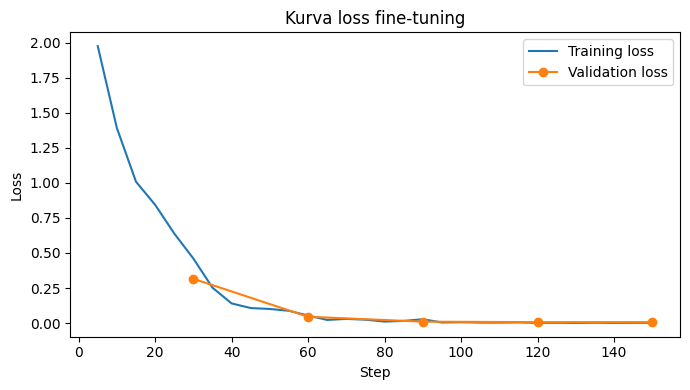

Adapter tersimpan di: /content/drive/MyDrive/Tugas_AI_Qwen/adapter_kopi_senja


In [ ]:
import matplotlib.pyplot as plt

log = trainer.state.log_history
tr = [(l["step"], l["loss"]) for l in log if "loss" in l]
ev = [(l["step"], l["eval_loss"]) for l in log if "eval_loss" in l]

plt.figure(figsize=(7, 4))
plt.plot(*zip(*tr), label="Training loss")
if ev:
    plt.plot(*zip(*ev), marker="o", label="Validation loss")
plt.xlabel("Step"); plt.ylabel("Loss"); plt.legend(); plt.title("Kurva loss fine-tuning")
plt.tight_layout()
plt.savefig(f"{BASE}/kurva_loss.png", dpi=150)
plt.show()

model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
print("Adapter tersimpan di:", ADAPTER_DIR)

## 11. Inference model **sesudah** fine-tuning

In [ ]:
model.eval()
model.config.use_cache = True

hasil_ft = []
for i, t in enumerate(TEST):
    hasil_ft.append(jawab(model, t["pertanyaan"]))
    print(f"[{i+1}/{len(TEST)}] {t['pertanyaan']}\n  -> {hasil_ft[-1][:150]}\n")

with open(f"{BASE}/hasil_finetuned.json", "w", encoding="utf-8") as f:
    json.dump(hasil_ft, f, ensure_ascii=False, indent=2)

[1/34] Kalau pesan Americano bayarnya berapa?
  -> Americano di Kopi Senja harganya Rp18.000.

[2/34] Kalau pesan Cafe Latte bayarnya berapa?
  -> Cafe Latte di Kopi Senja harganya Rp25.000.

[3/34] Kalau pesan Caramel Macchiato bayarnya berapa?
  -> Caramel Macchiato di Kopi Senja harganya Rp28.000.

[4/34] Kalau pesan V60 Manual Brew bayarnya berapa?
  -> V60 Manual Brew di Kopi Senja harganya Rp27.000.

[5/34] Kalau pesan Matcha Latte bayarnya berapa?
  -> Matcha Latte di Kopi Senja harganya Rp26.000.

[6/34] Kalau pesan Croissant Butter bayarnya berapa?
  -> Croissant Butter di Kopi Senja harganya Rp20.000.

[7/34] Kalau pesan Nasi Goreng Kampung bayarnya berapa?
  -> Nasi Goreng Kampung di Kopi Senja harganya Rp28.000.

[8/34] Kalau pesan Kopi Susu Senja bayarnya berapa?
  -> Kopi Susu Senja di Kopi Senja harganya Rp25.000.

[9/34] Ceritakan dong soal Kopi Susu Senja.
  -> Kopi Susu Senja adalah menu kopi kami. Menu andalan Kopi Senja: espresso, susu segar, dan gula aren dengan ra

## 12. Evaluasi: sebelum vs sesudah
- **Akurasi fakta**: 1 jika semua kata kunci fakta muncul pada jawaban, 0 jika tidak.
- **ROUGE-L**: kemiripan dengan jawaban referensi.
- File CSV juga disiapkan untuk **penilaian manual** (skala 1-5).

In [ ]:
import pandas as pd

if "hasil_base" not in globals():
    hasil_base = json.load(open(f"{BASE}/hasil_base.json", encoding="utf-8"))

rows = []
for t, b, f in zip(TEST, hasil_base, hasil_ft):
    rows.append({
        "jenis": t["jenis"], "pertanyaan": t["pertanyaan"], "referensi": t["referensi"],
        "jawaban_base": b, "jawaban_finetuned": f,
        "akurasi_base": skor_kunci(b, t["kunci"]), "akurasi_ft": skor_kunci(f, t["kunci"]),
        "rougeL_base": round(rouge_l(t["referensi"], b), 3), "rougeL_ft": round(rouge_l(t["referensi"], f), 3),
    })
df = pd.DataFrame(rows)

print("=== RINGKASAN KESELURUHAN ===")
print(df[["akurasi_base", "akurasi_ft", "rougeL_base", "rougeL_ft"]].mean().round(3))
print("\n=== PER JENIS PERTANYAAN ===")
print(df.groupby("jenis")[["akurasi_base", "akurasi_ft"]].mean().round(2))

df.to_csv(f"{BASE}/evaluasi_otomatis.csv", index=False, encoding="utf-8-sig")

# Template penilaian manual (isi skala 1-5 untuk tiap kolom)
manual = df[["pertanyaan", "referensi", "jawaban_base", "jawaban_finetuned"]].copy()
for kolom in ["fakta_base", "relevansi_base", "gaya_base", "tanpa_halusinasi_base",
              "fakta_ft", "relevansi_ft", "gaya_ft", "tanpa_halusinasi_ft"]:
    manual[kolom] = ""
manual.to_csv(f"{BASE}/penilaian_manual.csv", index=False, encoding="utf-8-sig")
df.head()

=== RINGKASAN KESELURUHAN ===
akurasi_base    0.029
akurasi_ft      0.941
rougeL_base     0.129
rougeL_ft       0.966
dtype: float64

=== PER JENIS PERTANYAAN ===
                 akurasi_base  akurasi_ft
jenis                                    
deskripsi                0.00        1.00
di_luar_topik            0.00        1.00
harga                    0.00        0.88
info                     0.09        0.91
kategori                 0.00        1.00
ketersediaan             0.00        1.00
perbandingan             0.00        1.00
tidak_diketahui          0.00        1.00


,jenis,pertanyaan,referensi,jawaban_base,jawaban_finetuned,akurasi_base,akurasi_ft,rougeL_base,rougeL_ft
0,harga,Kalau pesan Americano bayarnya berapa?,Americano di Kopi Senja harganya Rp18.000.,Pesanan Americano biasanya dihargai sekitar 10...,Americano di Kopi Senja harganya Rp18.000.,0,1,0.095,1.0
1,harga,Kalau pesan Cafe Latte bayarnya berapa?,Cafe Latte di Kopi Senja harganya Rp25.000.,"Pesanan ""Cafe Latte"" biasanya dihargai sekitar...",Cafe Latte di Kopi Senja harganya Rp25.000.,0,1,0.200,1.0
2,harga,Kalau pesan Caramel Macchiato bayarnya berapa?,Caramel Macchiato di Kopi Senja harganya Rp28....,Pesanan Caramel Macchiato biasanya dijual seki...,Caramel Macchiato di Kopi Senja harganya Rp28....,0,1,0.160,1.0
3,harga,Kalau pesan V60 Manual Brew bayarnya berapa?,V60 Manual Brew di Kopi Senja harganya Rp27.000.,Pesanan untuk kopi V60 manual brew biasanya di...,V60 Manual Brew di Kopi Senja harganya Rp27.000.,0,1,0.172,1.0
4,harga,Kalau pesan Matcha Latte bayarnya berapa?,Matcha Latte di Kopi Senja harganya Rp26.000.,Pesan Matcha Latte biasanya dijual sekitar 10-...,Matcha Latte di Kopi Senja harganya Rp26.000.,0,1,0.148,1.0


## 13. Antarmuka Gradio (model dasar vs model fine-tuned berdampingan)

In [3]:
import gradio as gr

def bandingkan(pertanyaan):
    if not pertanyaan.strip():
        return "", ""
    with model.disable_adapter():
        jawaban_base = jawab(model, pertanyaan)
    jawaban_ft = jawab(model, pertanyaan)
    return jawaban_base, jawaban_ft

demo = gr.Interface(
    fn=bandingkan,
    inputs=gr.Textbox(label="Pertanyaan pelanggan", lines=2, placeholder="Contoh: Berapa harga Americano?"),
    outputs=[gr.Textbox(label="Model Dasar (sebelum fine-tuning)"), gr.Textbox(label="Model Fine-tuned (Kopi Senja)")],
    title="Chatbot Kopi Senja - Qwen + LoRA",
    description="Bandingkan jawaban model dasar dengan model yang sudah di-fine-tuning.",
    examples=["Berapa harga Cafe Latte?", "Jam berapa Kopi Senja tutup hari Sabtu?", "Ada promo apa saja?",
              "Password wifinya apa?", "Siapa presiden Amerika?"],
)
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e004315a1675fb21f3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 14. (Opsional) Memuat ulang adapter di sesi baru
Jika Colab terputus, jalankan sel 2 (konfigurasi) lalu sel ini, tanpa training ulang.
Setelah itu jalankan sel Gradio.

In [2]:
import torch, json
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
dasar = AutoModelForCausalLM.from_pretrained(MODEL_NAME, quantization_config=bnb, device_map="auto")
model = PeftModel.from_pretrained(dasar, ADAPTER_DIR)
model.eval()

@torch.no_grad()
def jawab(model, pertanyaan, max_new_tokens=160):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": pertanyaan}]
    teks = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(teks, return_tensors="pt", add_special_tokens=False).to(model.device)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                         temperature=None, top_p=None, top_k=None, pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

print(jawab(model, "Jam berapa Kopi Senja buka?"))

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Kopi Senja buka Senin-Jumat pukul 08.00-22.00, Sabtu-Minggu pukul 07.00-23.00, dan hari libur nasional pukul 09.00-21.00.
